# Analisi Adattiva di Motifs e Discords

Questo notebook implementa un'analisi avanzata tramite Matrix Profile. Tutti i parametri fondamentali sono centralizzati nella **Cella di Configurazione** per permettere un adattamento dinamico dell'intera pipeline.


In [96]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import stumpy
from sklearn.cluster import KMeans
from sktime.clustering.k_means import TimeSeriesKMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

try:
    from tslearn.shapelets import ShapeletModel
    from tslearn.utils import to_time_series_dataset
except ImportError:
    print("tslearn non trovata. Puoi installarla con !pip install tslearn")

import warnings
warnings.filterwarnings('ignore')

print("Caricamento dataset normalizzato (Instance-wise)...")
ts_data = pd.read_pickle('ts_normalized.pkl.gz')
print(f"Trovate {len(ts_data)} serie storiche.")


tslearn non trovata. Puoi installarla con !pip install tslearn
Caricamento dataset normalizzato (Instance-wise)...
Trovate 4437 serie storiche.


## Pannello di Configurazione Globale
Modifica liberamente i parametri in questa cella. Tutto il codice, le estrazioni, i plot e le etichette si adatteranno in automatico!


In [103]:
# --- CONFIGURAZIONE GLOBALE ---
m = 8                          # Window size (es. 16 campionamenti = 8 ore se step=30min)
target_features = ['enmo', 'anglez']         # Variabile su cui calcolare il Matrix Profile (es. 'enmo', 'anglez', 'light')

k_clusters_motif = 3            # Numero di cluster desiderati per l'analisi dei Motif DTW
k_clusters_multi = 4            # Numero di cluster per l'analisi Multivariata Dataset-wise

top_k_motifs = 2                # Quanti Motif estrarre per ogni time series
top_k_discords = 2              # Quanti Discord estrarre per ogni time series

n_shapelets = 3                 # Numero di Shapelet da estrarre

# Variabile di supporto per stampare le etichette di tempo automaticamente
h_str = f"{m/2:g} ore"
print("Parametri configurati correttamente!")


Parametri configurati correttamente!


## Strategia A: Analisi sui Medoidi
Applichiamo il Matrix Profile sui medoidi pre-calcolati dal clustering globale. Questo estrae e visualizza i pattern più frequenti e le anomalie sui prototipi dei bambini.



ANALISI SULLA FEATURE: enmo


--- ANALISI DEL MEDOIDE 1452 (enmo) ---
I Top-2 Motifs sono stati trovati. Esempio Top-1 agli indici: [np.int64(68), np.int64(131), 142]
   -> Questo significa che i blocchi di 4 ore che iniziano a questi step sono risultati quasi identici (routine).
I Top-2 Discords sono stati trovati agli indici: [163 189]
   -> Le finestre di 4 ore che iniziano a questi step sono le più uniche e anomale del tracciato.



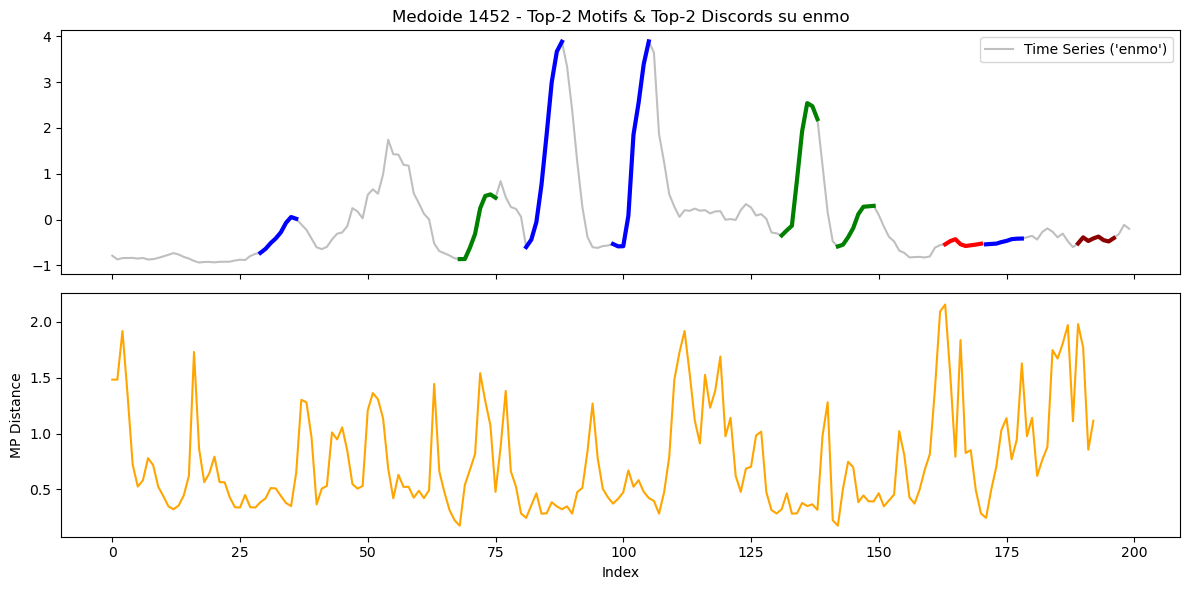


--- ANALISI DEL MEDOIDE 2791 (enmo) ---
I Top-2 Motifs sono stati trovati. Esempio Top-1 agli indici: [np.int64(53), 71]
   -> Questo significa che i blocchi di 4 ore che iniziano a questi step sono risultati quasi identici (routine).
I Top-2 Discords sono stati trovati agli indici: [153   0]
   -> Le finestre di 4 ore che iniziano a questi step sono le più uniche e anomale del tracciato.



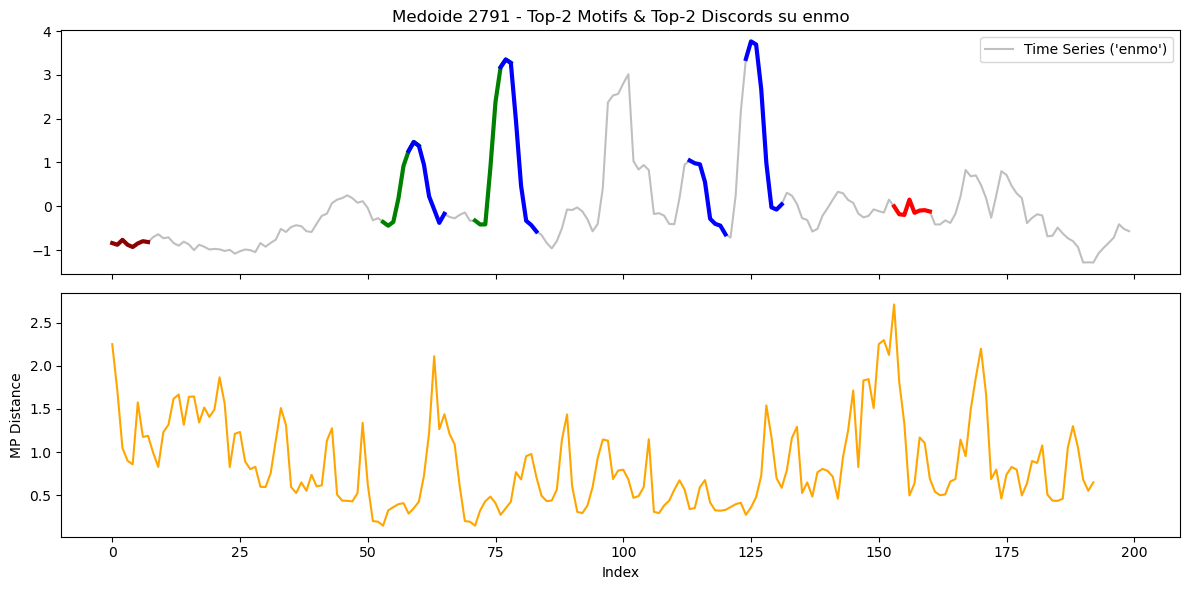


--- ANALISI DEL MEDOIDE 2734 (enmo) ---
I Top-1 Motifs sono stati trovati. Esempio Top-1 agli indici: [np.int64(33), np.int64(90), np.int64(110), np.int64(130), 153, np.int64(172)]
   -> Questo significa che i blocchi di 4 ore che iniziano a questi step sono risultati quasi identici (routine).
I Top-2 Discords sono stati trovati agli indici: [  0 191]
   -> Le finestre di 4 ore che iniziano a questi step sono le più uniche e anomale del tracciato.



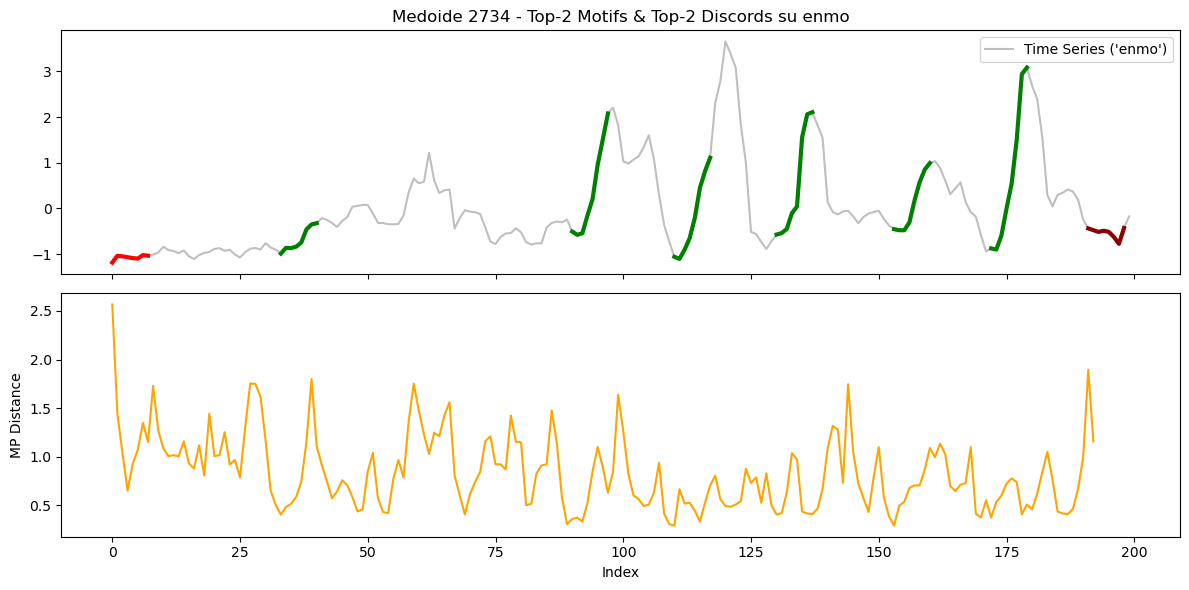


--- ANALISI DEL MEDOIDE 311 (enmo) ---
I Top-2 Motifs sono stati trovati. Esempio Top-1 agli indici: [np.int64(119), 147]
   -> Questo significa che i blocchi di 4 ore che iniziano a questi step sono risultati quasi identici (routine).
I Top-2 Discords sono stati trovati agli indici: [ 50 129]
   -> Le finestre di 4 ore che iniziano a questi step sono le più uniche e anomale del tracciato.



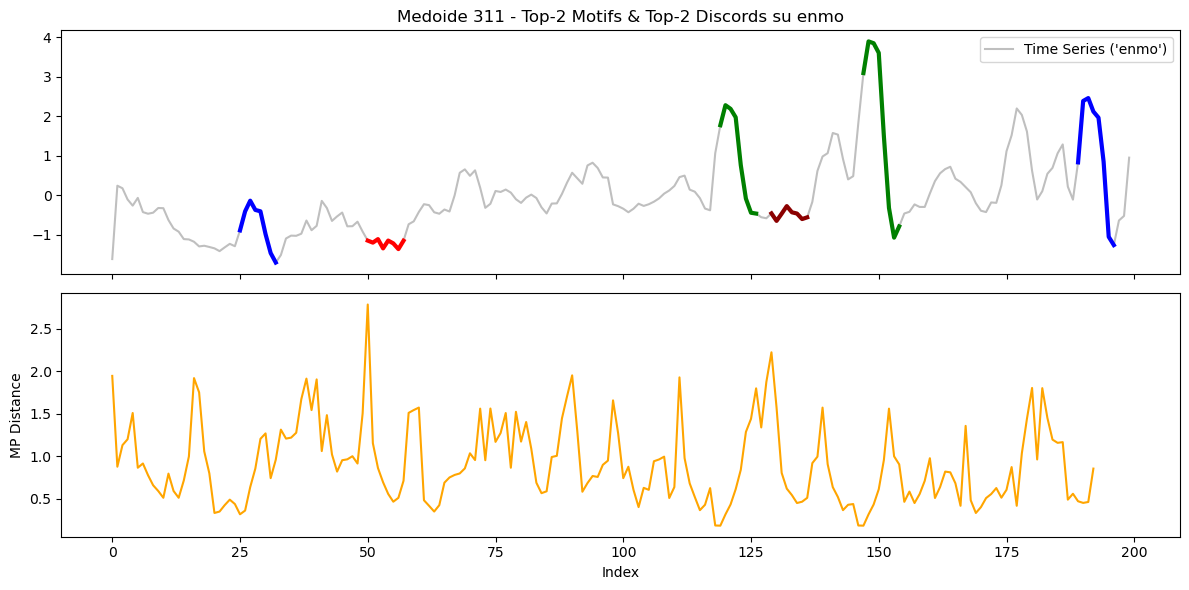


ANALISI SULLA FEATURE: anglez


--- ANALISI DEL MEDOIDE 1452 (anglez) ---
I Top-2 Motifs sono stati trovati. Esempio Top-1 agli indici: [np.int64(93), 181]
   -> Questo significa che i blocchi di 4 ore che iniziano a questi step sono risultati quasi identici (routine).
I Top-2 Discords sono stati trovati agli indici: [64 59]
   -> Le finestre di 4 ore che iniziano a questi step sono le più uniche e anomale del tracciato.



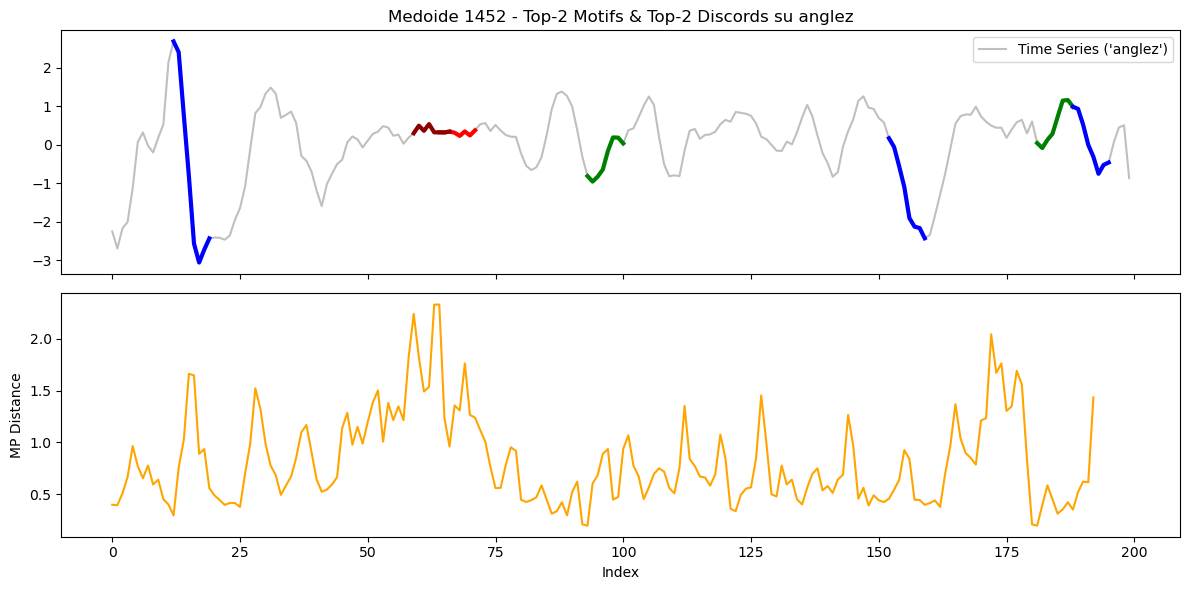


--- ANALISI DEL MEDOIDE 2791 (anglez) ---
I Top-2 Motifs sono stati trovati. Esempio Top-1 agli indici: [np.int64(44), 57, np.int64(77)]
   -> Questo significa che i blocchi di 4 ore che iniziano a questi step sono risultati quasi identici (routine).
I Top-2 Discords sono stati trovati agli indici: [168 102]
   -> Le finestre di 4 ore che iniziano a questi step sono le più uniche e anomale del tracciato.



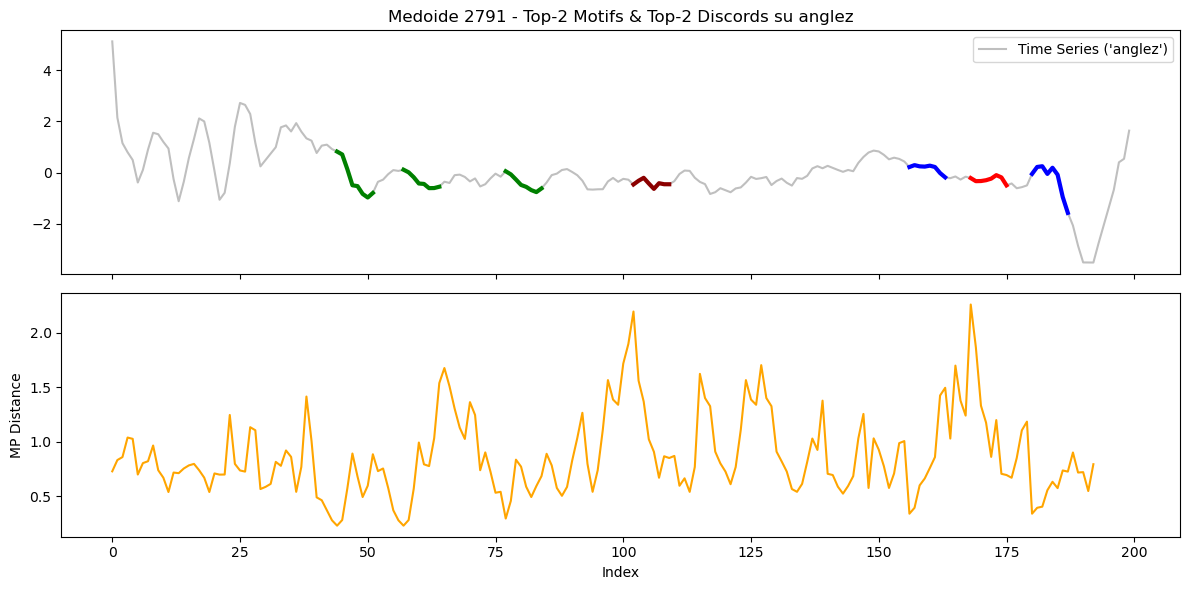


--- ANALISI DEL MEDOIDE 2734 (anglez) ---
I Top-2 Motifs sono stati trovati. Esempio Top-1 agli indici: [np.int64(41), 191]
   -> Questo significa che i blocchi di 4 ore che iniziano a questi step sono risultati quasi identici (routine).
I Top-2 Discords sono stati trovati agli indici: [183 145]
   -> Le finestre di 4 ore che iniziano a questi step sono le più uniche e anomale del tracciato.



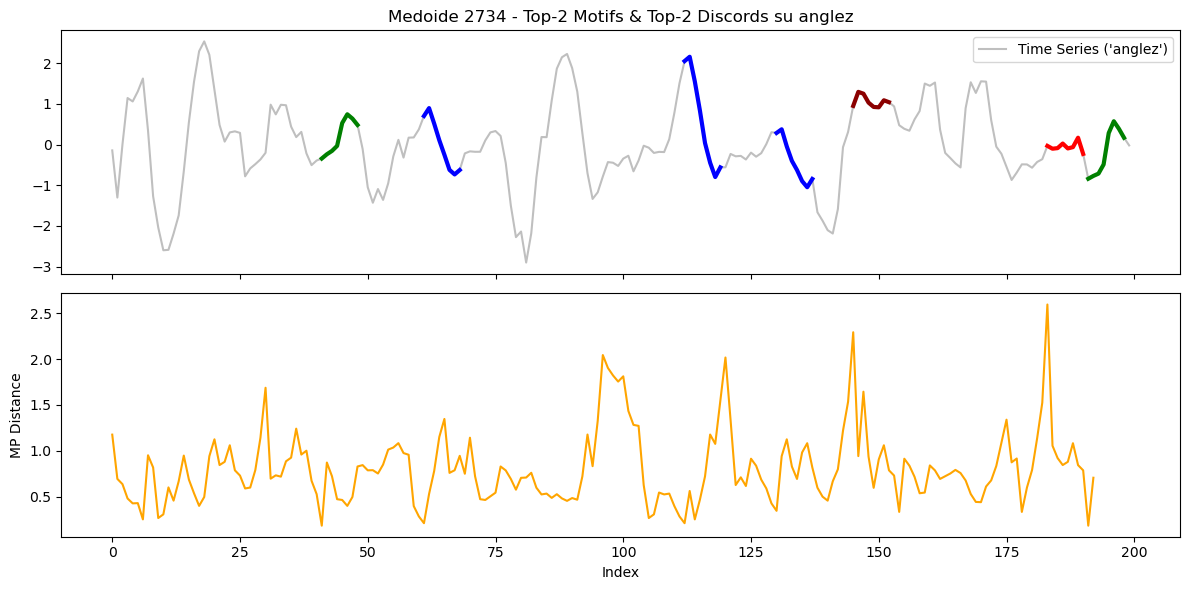


--- ANALISI DEL MEDOIDE 311 (anglez) ---
I Top-2 Motifs sono stati trovati. Esempio Top-1 agli indici: [np.int64(13), 113]
   -> Questo significa che i blocchi di 4 ore che iniziano a questi step sono risultati quasi identici (routine).
I Top-2 Discords sono stati trovati agli indici: [148 132]
   -> Le finestre di 4 ore che iniziano a questi step sono le più uniche e anomale del tracciato.



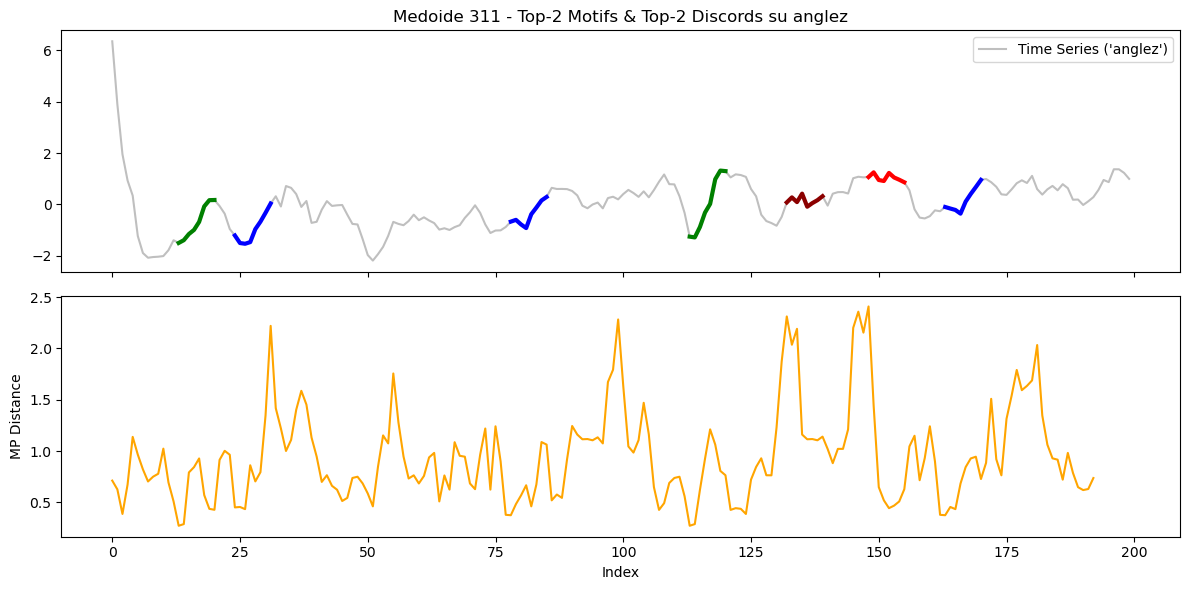

In [104]:
from matrixprofile import motifs
from matrixprofile.discords import discords

medoid_idx = [1452, 2791, 2734, 311]
medoids = [ts_data[i] for i in medoid_idx]

for target_feature in target_features:
    print(f"\n{'='*50}\nANALISI SULLA FEATURE: {target_feature}\n{'='*50}\n")
    
    for i, ts_df in enumerate(medoids):
        ts_medoide = ts_df[target_feature].values.astype(np.float64)

        # Calcoliamo il MP con stumpy per avere la matrice base
        mp_full = stumpy.stump(ts_medoide, m)
        mp_dist = mp_full[:, 0].astype(np.float64)
        mpi = mp_full[:, 1].astype(np.int64)

        # Estrattore Motifs tramite matrixprofile-ts come richiesto
        mo, mod = motifs.motifs(ts_medoide, (mp_dist, mpi), max_motifs=top_k_motifs)
        
        # Estrattore Discords tramite matrixprofile-ts come richiesto
        anoms = discords(mp_dist, ex_zone=int(m/2), k=top_k_discords)

        print(f"\n--- ANALISI DEL MEDOIDE {medoid_idx[i]} ({target_feature}) ---")
        if len(mo) > 0:
            print(f"I Top-{len(mo)} Motifs sono stati trovati. Esempio Top-1 agli indici: {mo[0]}")
            print(f"   -> Questo significa che i blocchi di {h_str} che iniziano a questi step sono risultati quasi identici (routine).")
        
        if len(anoms) > 0:
            print(f"I Top-{len(anoms)} Discords sono stati trovati agli indici: {anoms}")
            print(f"   -> Le finestre di {h_str} che iniziano a questi step sono le più uniche e anomale del tracciato.\n")

        # Configurazione struttura subplots originale: 1 per le TS con Motifs/Discords, 1 per il Matrix Profile
        fig, axs = plt.subplots(2, 1, sharex=True, figsize=(12, 6))
        
        # PLOT DEI MOTIFS E DISCORDS INSIEME
        axs[0].plot(ts_medoide, label=f"Time Series ('{target_feature}')", color='gray', alpha=0.5)
        axs[0].set_title(f"Medoide {medoid_idx[i]} - Top-{top_k_motifs} Motifs & Top-{top_k_discords} Discords su {target_feature}")
        
        # Plot Motifs
        colors_mo = ['g', 'b', 'm', 'c', 'y'][:max(1, len(mo))]
        for motif_group, d, c in zip(mo, mod, colors_mo):
            for idx in motif_group:
                m_shape = ts_medoide[idx : idx + m]
                axs[0].plot(range(idx, idx + m), m_shape, color=c, lw=3)
                
        # Plot Discords (in rosso)
        colors_anom = ['r', 'darkred', 'salmon', 'orange', 'k'][:max(1, len(anoms))]
        for a, c in zip(anoms, colors_anom):
            a_shape = ts_medoide[a : a + m]
            axs[0].plot(range(a, a + m), a_shape, color=c, lw=3)
            
        axs[0].legend(loc='upper right')

        # PLOT DELLA MATRIX PROFILE DISTANCE (Valli e Picchi)
        axs[1].plot(mp_dist, color='orange')
        axs[1].set_ylabel('MP Distance')
        axs[1].set_xlabel('Index')
        
        plt.tight_layout()
        plt.show()


## (**LASCIA PERDERE**) Strategia B: Estrazione Dinamica dei Motif
Questo blocco sfrutta il parametro `top_k_motifs`. Esegue iterativamente il Matrix Profile ed estrae le abitudini multiple "nascondendo" le precedenti tramite Exclusion Zone.



ESTRAZIONE E CLUSTERING SULLA FEATURE: enmo

Estrazione dinamica dei Top-2 Motif sulla feature 'enmo' da 200 serie...
Creato dataset di 400 Motif estratti per enmo.
Esecuzione TimeSeriesKMeans (K=3) con DTW...


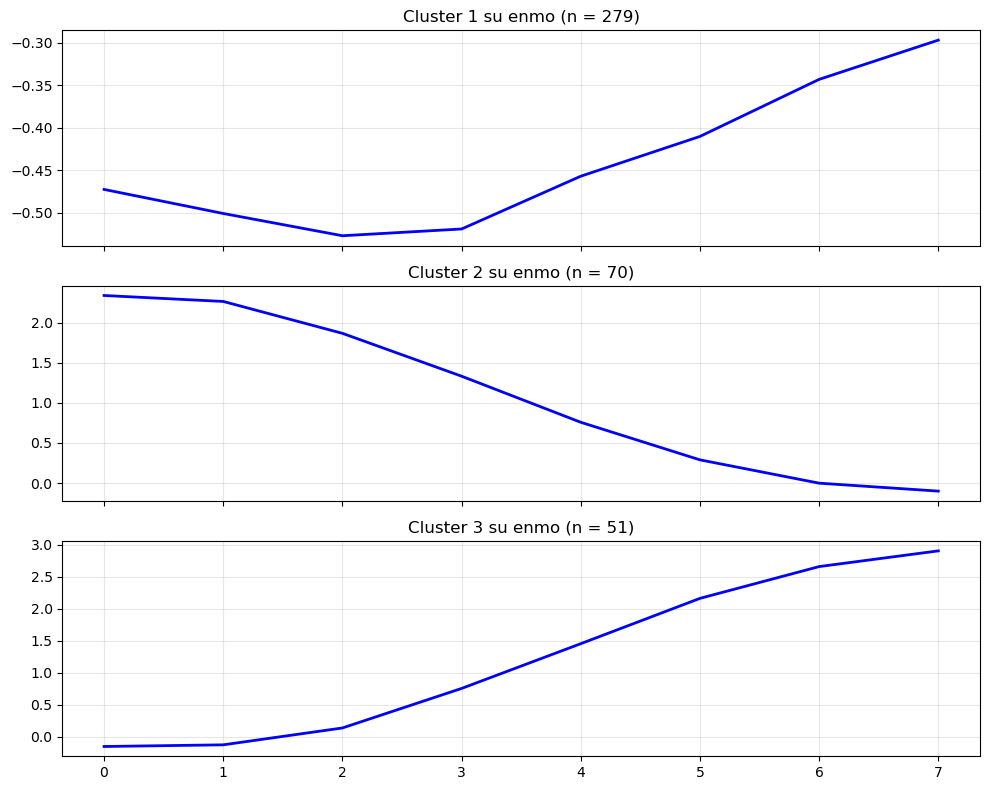

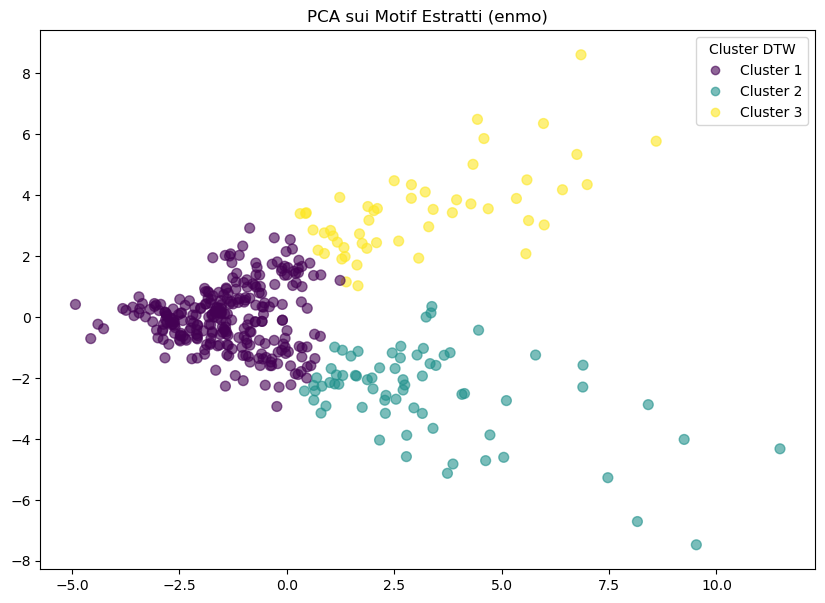


--- PROFILO NUMERICO E INTERPRETAZIONE CLUSTER UNIVARIATI (enmo) ---


,Media,Dev.Std,Max,Min
Cluster,,,,
1,-0.440668,0.078625,-0.296986,-0.526705
2,1.092852,0.932393,2.337590,-0.100585
3,1.224020,1.168619,2.903522,-0.151870



Interpretazione Univariata (enmo):
- Cluster 1: Pattern con intensità media normalizzata di -0.44. Caratteristica: Bassa variazione (pattern stabile/stasi).
- Cluster 2: Pattern con intensità media normalizzata di 1.09. Caratteristica: Alta variazione (pattern dinamico).
- Cluster 3: Pattern con intensità media normalizzata di 1.22. Caratteristica: Alta variazione (pattern dinamico).

ESTRAZIONE E CLUSTERING SULLA FEATURE: anglez

Estrazione dinamica dei Top-2 Motif sulla feature 'anglez' da 200 serie...
Creato dataset di 400 Motif estratti per anglez.
Esecuzione TimeSeriesKMeans (K=3) con DTW...


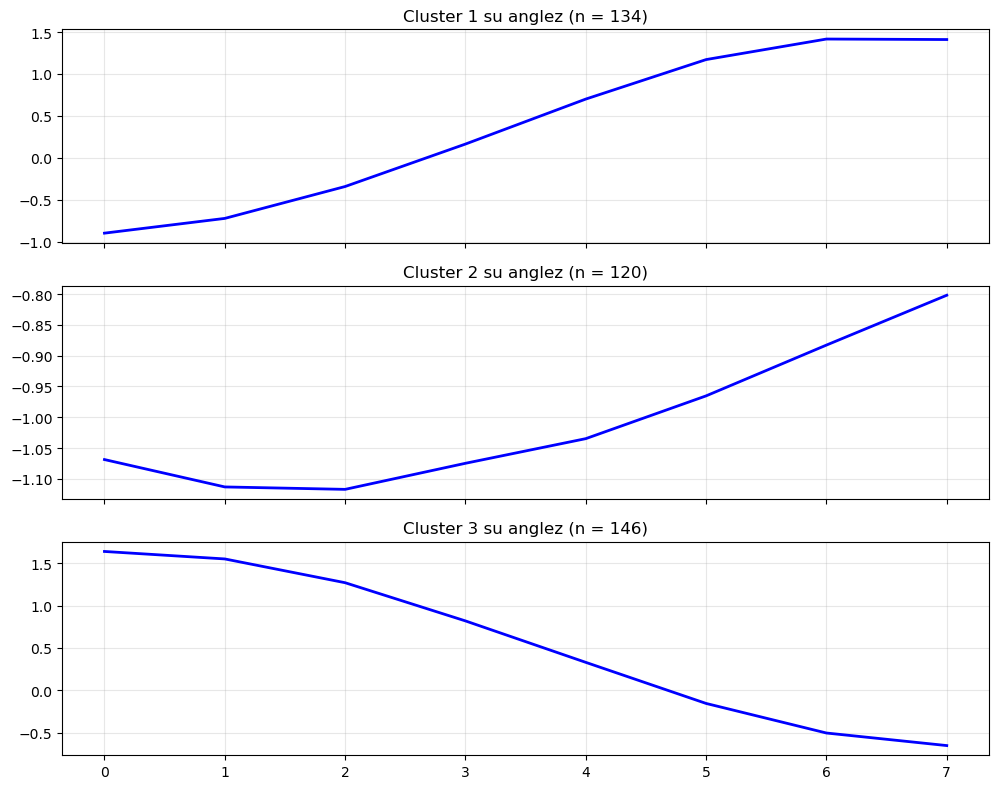

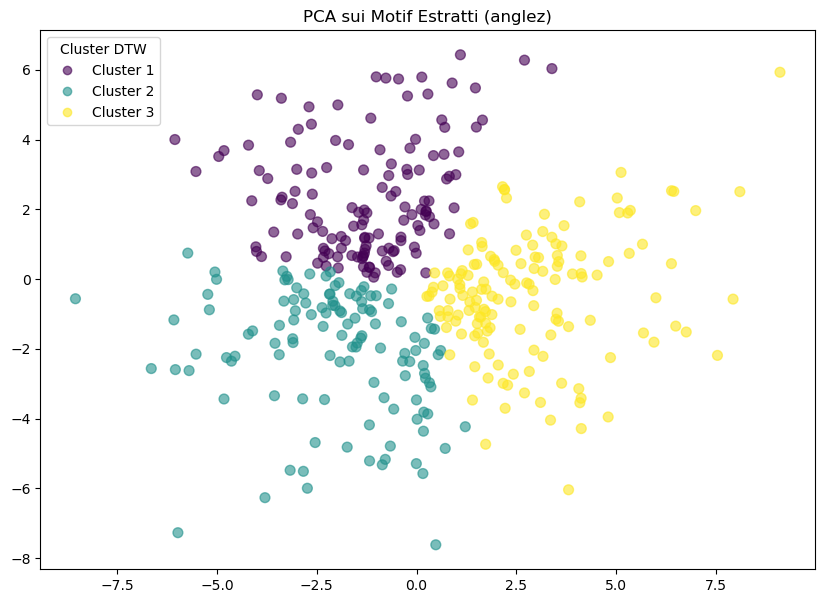


--- PROFILO NUMERICO E INTERPRETAZIONE CLUSTER UNIVARIATI (anglez) ---


,Media,Dev.Std,Max,Min
Cluster,,,,
1,0.361449,0.886695,1.416143,-0.900288
2,-1.007277,0.107156,-0.801785,-1.117109
3,0.537645,0.858122,1.640554,-0.653065



Interpretazione Univariata (anglez):
- Cluster 1: Pattern con intensità media normalizzata di 0.36. Caratteristica: Alta variazione (pattern dinamico).
- Cluster 2: Pattern con intensità media normalizzata di -1.01. Caratteristica: Bassa variazione (pattern stabile/stasi).
- Cluster 3: Pattern con intensità media normalizzata di 0.54. Caratteristica: Alta variazione (pattern dinamico).


In [99]:
from IPython.display import display

# Analizziamo un subset per rapidità
subset_ts = ts_data[:200] 

for target_feature in target_features:
    print(f"\n{'='*50}\nESTRAZIONE E CLUSTERING SULLA FEATURE: {target_feature}\n{'='*50}\n")
    
    motif_dataset = []
    print(f"Estrazione dinamica dei Top-{top_k_motifs} Motif sulla feature '{target_feature}' da {len(subset_ts)} serie...")

    for ts_df in subset_ts:
        ts_val = ts_df[target_feature].values.astype(np.float64)
        if len(ts_val) <= m:
            continue
            
        mp_local = stumpy.stump(ts_val, m)
        mp_dist = mp_local[:, 0].copy().astype(np.float64)
        
        # Ciclo di estrazione Top-K Motif
        for k in range(top_k_motifs):
            if np.isinf(mp_dist).all():
                break
                
            m_idx = np.argmin(mp_dist)
            
            motif_subseq = ts_val[m_idx : m_idx + m]
            if not np.isnan(motif_subseq).any() and not np.isinf(mp_dist[m_idx]):
                motif_dataset.append(motif_subseq)
                
            excl_start = max(0, m_idx - int(np.ceil(m/2)))
            excl_end = min(len(mp_dist), m_idx + int(np.ceil(m/2)))
            mp_dist[excl_start:excl_end] = np.inf
            
            nn_idx = mp_local[m_idx, 1]
            if nn_idx >= 0:
                excl_nn_start = max(0, nn_idx - int(np.ceil(m/2)))
                excl_nn_end = min(len(mp_dist), nn_idx + int(np.ceil(m/2)))
                mp_dist[excl_nn_start:excl_nn_end] = np.inf

    motif_dataset = np.array(motif_dataset)
    print(f"Creato dataset di {motif_dataset.shape[0]} Motif estratti per {target_feature}.")

    # DTW KMeans sui Motif estratti
    print(f"Esecuzione TimeSeriesKMeans (K={k_clusters_motif}) con DTW...")
    kmeans_dtw = TimeSeriesKMeans(n_clusters=k_clusters_motif, metric="dtw", init_algorithm="kmeans++", n_init=5, random_state=42, distance_params={"window": 0.05})
    motif_clusters = kmeans_dtw.fit_predict(motif_dataset)

    # Visualizzazione Centroidi
    fig, axs = plt.subplots(k_clusters_motif, 1, figsize=(10, 8), sharex=True)
    for i in range(k_clusters_motif):
        centroid = kmeans_dtw.cluster_centers_[i].flatten()
        axs[i].plot(centroid, color='blue', linewidth=2)
        axs[i].set_title(f'Cluster {i+1} su {target_feature} (n = {sum(motif_clusters==i)})')
        axs[i].grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    # PCA
    pca = PCA(n_components=2)
    motif_pca = pca.fit_transform(motif_dataset)
    plt.figure(figsize=(10, 7))
    scatter = plt.scatter(motif_pca[:, 0], motif_pca[:, 1], c=motif_clusters, cmap='viridis', alpha=0.6, s=50)
    handles, _ = scatter.legend_elements()
    plt.legend(handles, [f"Cluster {i+1}" for i in range(k_clusters_motif)], title="Cluster DTW")
    plt.title(f"PCA sui Motif Estratti ({target_feature})")
    plt.show()

    # Profilo Numerico Univariato
    print(f"\n--- PROFILO NUMERICO E INTERPRETAZIONE CLUSTER UNIVARIATI ({target_feature}) ---")
    centroid_stats = []
    for i in range(k_clusters_motif):
        c = kmeans_dtw.cluster_centers_[i].flatten()
        centroid_stats.append({
            'Cluster': i+1,
            'Media': np.mean(c),
            'Dev.Std': np.std(c),
            'Max': np.max(c),
            'Min': np.min(c)
        })
    df_centroids = pd.DataFrame(centroid_stats).set_index('Cluster')
    display(df_centroids)

    print(f"\nInterpretazione Univariata ({target_feature}):")
    for i, row in df_centroids.iterrows():
        stability = "Alta variazione (pattern dinamico)" if row['Dev.Std'] > df_centroids['Dev.Std'].mean() else "Bassa variazione (pattern stabile/stasi)"
        print(f"- Cluster {i}: Pattern con intensità media normalizzata di {row['Media']:.2f}. Caratteristica: {stability}.")


## Clustering Multivariato Dataset-wise
Qui incrociamo il Motif con le *altre variabili* del dataset grezzo (intensità assolute) per creare un cluster basato sul contesto.


Caricamento dataset grezzo (valori assoluti)...
Estrazione contesto multivariato ancorato sui Motif trovati su 'enmo'...

Esecuzione KMeans Multivariato (K=4)...

--- MEDIE NUMERICHE DEI VALORI PER CLUSTER MULTIVARIATO ---


,enmo_mean,anglez_mean,light_mean,X_mean,Y_mean,Z_mean,sii_binary
Cluster_Multivariato,,,,,,,
0,0.057009,-12.940083,36.206848,-0.482850,0.016386,-0.185367,0.294118
1,0.050639,-27.644791,54.847248,0.395325,0.092439,-0.380580,0.370968
2,0.039210,23.264502,27.218287,0.249739,-0.109718,0.341037,0.479167
3,0.432864,11.220393,74.773453,-0.315724,0.303522,0.218776,0.200000



--- INTERPRETAZIONE DEI CLUSTER MULTIVARIATI ---
- Cluster 1:
   * Attività media (enmo): 0.0570
   * Inclinazione media polso (anglez): -12.94
   * Luce ambientale media: 36.2
   * Correlazione con Problematic Internet Use (sii_binary): 29.4% dei bambini in questo cluster sono 'casi problematici'.
- Cluster 2:
   * Attività media (enmo): 0.0506
   * Inclinazione media polso (anglez): -27.64
   * Luce ambientale media: 54.8
   * Correlazione con Problematic Internet Use (sii_binary): 37.1% dei bambini in questo cluster sono 'casi problematici'.
- Cluster 3:
   * Attività media (enmo): 0.0392
   * Inclinazione media polso (anglez): 23.26
   * Luce ambientale media: 27.2
   * Correlazione con Problematic Internet Use (sii_binary): 47.9% dei bambini in questo cluster sono 'casi problematici'.
- Cluster 4:
   * Attività media (enmo): 0.4329
   * Inclinazione media polso (anglez): 11.22
   * Luce ambientale media: 74.8
   * Correlazione con Problematic Internet Use (sii_binary): 20.0% dei 

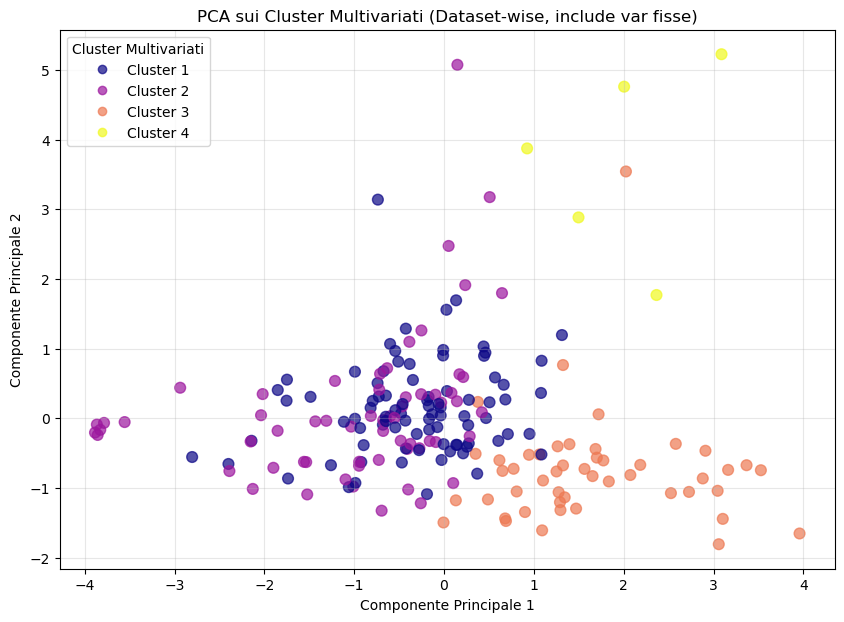

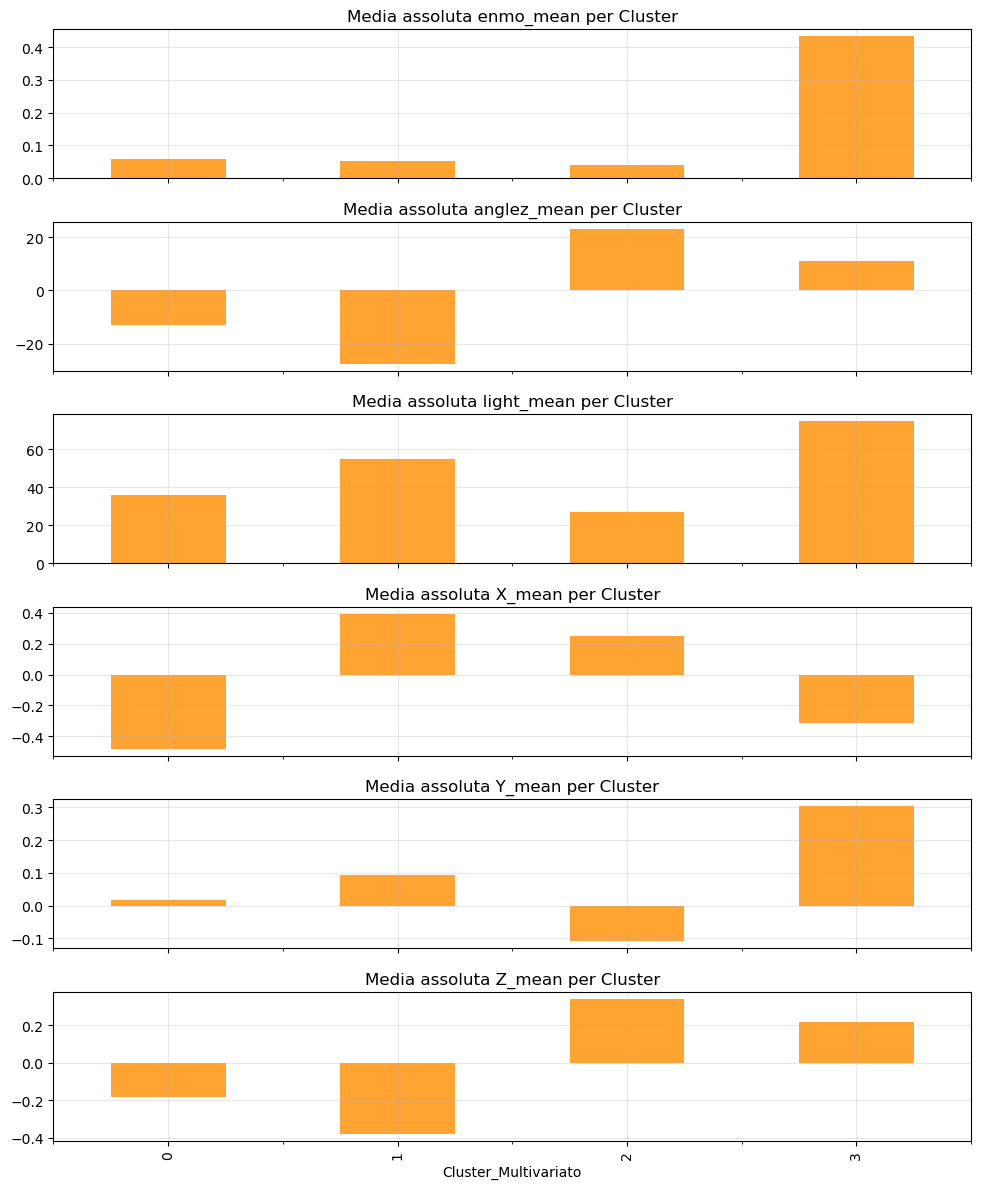

In [100]:
from IPython.display import display

print("Caricamento dataset grezzo (valori assoluti)...")
ts_raw_data = pd.read_pickle('CMI_timeseries_dataset.pkl.gz')

motif_features_list = []

# Usiamo la prima feature della lista (enmo) come ancora temporale
anchor_feature = target_features[0]
print(f"Estrazione contesto multivariato ancorato sui Motif trovati su '{anchor_feature}'...")

for i, ts_df in enumerate(subset_ts):
    ts_val = ts_df[anchor_feature].values.astype(np.float64)
    if len(ts_val) <= m: continue
        
    mp_local = stumpy.stump(ts_val, m)
    # Estraiamo il primo motif
    m_idx = np.argmin(mp_local[:, 0])
    
    motif_raw_df = ts_raw_data[i].iloc[m_idx : m_idx + m]
    
    features = {
        'enmo_mean': motif_raw_df['enmo'].mean(),
        'anglez_mean': motif_raw_df['anglez'].mean(),
        'light_mean': motif_raw_df['light'].mean(),
        'X_mean': motif_raw_df['X'].mean(),
        'Y_mean': motif_raw_df['Y'].mean(),
        'Z_mean': motif_raw_df['Z'].mean(),
        'weekday_mode': str(int(motif_raw_df['weekday'].mode().iloc[0])),
        'quarter_mode': str(int(motif_raw_df['quarter'].mode().iloc[0])), # Variabile Fissa
        'sii_binary': motif_raw_df['sii_binary'].iloc[0] # Variabile Target (NON usata per clustering)
    }
    motif_features_list.append(features)

df_motif_features = pd.DataFrame(motif_features_list)
# Dummy per le variabili categoriche/fisse
df_motif_encoded = pd.get_dummies(df_motif_features, columns=['weekday_mode', 'quarter_mode'])

cols_to_drop = ['sii_binary']
X_cluster = df_motif_encoded.drop(columns=cols_to_drop)

scaler = StandardScaler()
numeric_cols = ['enmo_mean', 'anglez_mean', 'light_mean', 'X_mean', 'Y_mean', 'Z_mean']
X_cluster[numeric_cols] = scaler.fit_transform(X_cluster[numeric_cols])
X_cluster = X_cluster.astype(float)

print(f"\nEsecuzione KMeans Multivariato (K={k_clusters_multi})...")
kmeans_multi = KMeans(n_clusters=k_clusters_multi, random_state=42)
multi_clusters = kmeans_multi.fit_predict(X_cluster)
df_motif_features['Cluster_Multivariato'] = multi_clusters

print("\n--- MEDIE NUMERICHE DEI VALORI PER CLUSTER MULTIVARIATO ---")
cluster_profiles = df_motif_features.groupby('Cluster_Multivariato').mean(numeric_only=True)
display(cluster_profiles)

print("\n--- INTERPRETAZIONE DEI CLUSTER MULTIVARIATI ---")
for i, row in cluster_profiles.iterrows():
    print(f"- Cluster {i+1}:")
    print(f"   * Attività media (enmo): {row['enmo_mean']:.4f}")
    print(f"   * Inclinazione media polso (anglez): {row['anglez_mean']:.2f}")
    print(f"   * Luce ambientale media: {row['light_mean']:.1f}")
    print(f"   * Correlazione con Problematic Internet Use (sii_binary): {row['sii_binary']*100:.1f}% dei bambini in questo cluster sono 'casi problematici'.")

# Visualizzazione PCA Multivariata
print("\nGenerazione PCA Multivariata...")
pca_multi = PCA(n_components=2)
X_pca_multi = pca_multi.fit_transform(X_cluster)
plt.figure(figsize=(10, 7))
scatter = plt.scatter(X_pca_multi[:, 0], X_pca_multi[:, 1], c=multi_clusters, cmap='plasma', alpha=0.7, s=60)
handles, _ = scatter.legend_elements()
plt.legend(handles, [f"Cluster {i+1}" for i in range(k_clusters_multi)], title="Cluster Multivariati")
plt.title(f"PCA sui Cluster Multivariati (Dataset-wise, include var fisse)")
plt.xlabel("Componente Principale 1")
plt.ylabel("Componente Principale 2")
plt.grid(True, alpha=0.3)
plt.show()

# Grafici a Barre
fig, axs = plt.subplots(len(numeric_cols), 1, figsize=(10, 12), sharex=True)
for j, col in enumerate(numeric_cols):
    cluster_profiles[col].plot(kind='bar', ax=axs[j], color='darkorange', alpha=0.8)
    axs[j].set_title(f'Media assoluta {col} per Cluster')
    axs[j].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## Analisi Comparativa: Shapelet
Estrae gli Shapelet sulla base di `target_feature` usando il numero definito `n_shapelets`.


In [101]:

for target_feature in target_features:
    print(f"\n{'='*50}\nESTRAZIONE SHAPELETS SULLA FEATURE: {target_feature}\n{'='*50}\n")
    
    X_train = []
    y_train = []
    for ts_df in subset_ts:
        X_train.append(ts_df[target_feature].values)
        y_train.append(ts_df['sii_binary'].iloc[0]) 

    try:
        print(f"Estrazione di {n_shapelets} Shapelet...")
        X_train_ts = to_time_series_dataset(X_train)
        shapelet_clf = ShapeletModel(n_shapelets_per_size={m: n_shapelets}, optimizer="sgd", weight_regularizer=.01, max_iter=50, random_state=42)
        shapelet_clf.fit(X_train_ts, y_train)

        fig, axs = plt.subplots(n_shapelets, 1, figsize=(10, 6), sharex=True)
        for i, shapelet in enumerate(shapelet_clf.shapelets_):
            axs[i].plot(shapelet, color='purple', linewidth=2)
            axs[i].set_title(f'Shapelet {i+1} su {target_feature} (Lunghezza {h_str})')
            axs[i].grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()
    except Exception as e:
        print(f"Shapelets saltati per {target_feature}: {e}")



ESTRAZIONE SHAPELETS SULLA FEATURE: enmo

Estrazione di 3 Shapelet...
Shapelets saltati per enmo: name 'to_time_series_dataset' is not defined

ESTRAZIONE SHAPELETS SULLA FEATURE: anglez

Estrazione di 3 Shapelet...
Shapelets saltati per anglez: name 'to_time_series_dataset' is not defined
